# Music-Aligned Physiological signal Processing

This notebook processes **one anonymised demo for ISMIR 2026 M4L**, using `BVP.csv`, `EDA.csv`, `IBI.csv` and `MyLog.csv` from the raw-session folder. It does not search other participant folders or modify source files.

**Workflow:** load raw timestamps and the music log → preprocess the continuous session → align each song to its logged playback interval → clean song-level IBI, EDA, and BVP → extract signal features → save aligned signals and feature tables.

## 1. Imports and settings

**What and why:** define one participant, explicit input/output folders and the reference settings.

BVP uses a fourth-order 0.5–8 Hz Butterworth bandpass. EDA uses a 2.58-SD outlier threshold and a 5-second Hann smoother. Both continuous channels discard the initial 60 seconds once, then use session-level min–max normalization **before** song segmentation. IBI is not min–max normalized: its interval units must be retained for HRV.

In [43]:
# Optional installation in a fresh environment:
%pip install numpy pandas scipy matplotlib neurokit2
%matplotlib inline

from pathlib import Path
import json
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display
import neurokit2 as nk

In [44]:
# A single explicit folder limits all input operations to demo01.
from google.colab import drive

# Mount Google Drive and authorize access when prompted.
drive.mount("/content/drive")

# Change this path to the actual folder location in your Google Drive.
PROJECT_DIR = Path(
    "/content/drive/MyDrive/ISMIR 2026 tutorial/Colab Notebooks/01 Physiological Signal Processing"
)

PARTICIPANT = "demo01"
RAW_DIR = PROJECT_DIR / PARTICIPANT
OUTPUT_DIR = PROJECT_DIR / "demo01_raw_pipeline_outputs"

LOG_TIMEZONE = "Asia/Hong_Kong"
STABILIZATION_S = 60
SMOOTHING_S = 5
OUTLIER_Z = 2.58
BVP_BAND_HZ = (0.5, 8)
DEMO_SONG_NO = 0

# Check source files before running the analysis.
assert RAW_DIR.name == PARTICIPANT
for name in ["BVP.csv", "EDA.csv", "IBI.csv", "MyLog.csv"]:
    if not (RAW_DIR / name).is_file():
        raise FileNotFoundError(f"Missing source file: {RAW_DIR / name}")

plt.rcParams.update({
    "figure.figsize": (11, 3.5),
    "axes.grid": True,
    "grid.alpha": 0.2,
})

print(f"Input folder: {RAW_DIR}")
print(f"Output folder: {OUTPUT_DIR}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Input folder: /content/drive/MyDrive/ISMIR 2026 tutorial/Colab Notebooks/01 Physiological Signal Processing/demo01
Output folder: /content/drive/MyDrive/ISMIR 2026 tutorial/Colab Notebooks/01 Physiological Signal Processing/demo01_raw_pipeline_outputs


## 2. Read raw signals and the music log

**What:** read the timestamp and sample rate from the first two rows of BVP/EDA, then read their samples. IBI has a different format: one header row containing the session timestamp, followed by **relative beat time in seconds and IBI in seconds**.

**Why:** retaining the original IBI event timestamps is essential. Accumulating interval durations would erase gaps in beat detection and place observations at incorrect positions in the song.

The log's original row number becomes `song_no` (starting at 0), just as in FANJIE. We use **`start_time` and `end_time`**, rather than `time_play`, for segmentation. The supplied log contains disagreements between these fields; the table below exposes them instead of silently changing playback boundaries.

In [45]:
def load_regular_signal(path):
    """Read an Empatica BVP/EDA file and build its original UTC sample timestamps."""
    with path.open() as file:
        start_unix = float(next(file).strip())
        sampling_rate = int(float(next(file).strip()))
    values = pd.read_csv(path, skiprows=2, header=None)[0].to_numpy(dtype=float)
    start = pd.to_datetime(start_unix, unit='s', utc=True)
    times = start + pd.to_timedelta(np.arange(len(values)) / sampling_rate, unit='s')
    frame = pd.DataFrame({'raw': values}, index=times)
    frame.index.name = 'timestamp_utc'
    return frame, sampling_rate


def load_ibi_signal(path):
    """Read timestamped IBI events; keep seconds and the device's true event timing."""
    with path.open() as file:
        start_unix = float(next(file).split(',')[0])
    frame = pd.read_csv(path, skiprows=1, header=None, names=['offset_s', 'ibi_s'])
    start = pd.to_datetime(start_unix, unit='s', utc=True)
    frame.index = start + pd.to_timedelta(frame['offset_s'].to_numpy(), unit='s')
    frame.index.name = 'timestamp_utc'
    return frame[['ibi_s']]


def load_music_log(path):
    """Read this participant's song boundaries and explicitly convert local time to UTC."""
    log = pd.read_csv(path)
    assert log['user_id'].eq(PARTICIPANT).all(), 'The log must contain only demo01.'
    log.insert(0, 'song_no', np.arange(len(log)))
    for field in ['start_time', 'end_time']:
        local = pd.to_datetime(log[field]).dt.tz_localize(LOG_TIMEZONE)
        log[field + '_utc'] = local.dt.tz_convert('UTC')
    log['play_duration_s'] = (log['end_time_utc'] - log['start_time_utc']).dt.total_seconds()
    assert log['play_duration_s'].gt(0).all(), 'Playback intervals must have positive duration.'
    return log


# Load exactly three source files and this participant's own log.
raw_bvp, bvp_fs = load_regular_signal(RAW_DIR / 'BVP.csv')
raw_eda, eda_fs = load_regular_signal(RAW_DIR / 'EDA.csv')
raw_ibi = load_ibi_signal(RAW_DIR / 'IBI.csv')
music_log = load_music_log(RAW_DIR / 'MyLog.csv')
assert (bvp_fs, eda_fs) == (64, 4), 'Unexpected sample rates.'
assert all(frame.index.is_monotonic_increasing for frame in [raw_bvp, raw_eda, raw_ibi])

print(f'{PARTICIPANT}: {len(music_log)} song-playback records')
print(f'BVP: {len(raw_bvp)} samples at {bvp_fs} Hz; EDA: {len(raw_eda)} samples at {eda_fs} Hz')
print(f'IBI: {len(raw_ibi)} timestamped intervals')
display(music_log[['song_no', 'song_id', 'start_time', 'end_time',
                   'play_duration_s', 'duration', 'time_play']])

demo01: 31 song-playback records
BVP: 210188 samples at 64 Hz; EDA: 13134 samples at 4 Hz
IBI: 1110 timestamped intervals


,song_no,song_id,start_time,end_time,play_duration_s,duration,time_play
0,0,262957,2019-08-15 15:42:20,2019-08-15 15:44:47,147.0,147.0,84
1,1,1071844,2019-08-15 15:45:18,2019-08-15 15:46:19,61.0,61.0,46
2,2,1094515,2019-08-15 15:46:56,2019-08-15 15:47:42,46.0,46.0,56
3,3,519565,2019-08-15 15:48:05,2019-08-15 15:48:44,39.0,39.0,35
4,4,1130631,2019-08-15 15:49:04,2019-08-15 15:49:49,45.0,45.0,45
5,5,1167225,2019-08-15 15:50:05,2019-08-15 15:51:03,58.0,58.0,59
6,6,187045,2019-08-15 15:51:25,2019-08-15 15:52:10,45.0,45.0,50
7,7,1083659,2019-08-15 15:52:24,2019-08-15 15:53:28,64.0,64.0,65
8,8,262957,2019-08-15 15:54:16,2019-08-15 15:54:48,32.0,32.0,31
9,9,737755,2019-08-15 15:54:59,2019-08-15 15:55:50,51.0,51.0,53


### Inspect the raw session

**What and why:** plot all three channels on the same session clock. The shaded initial 60 seconds identify the stabilization interval removed from BVP and EDA. IBI points use their actual timestamps and may contain long gaps. No synthetic beats are inserted.

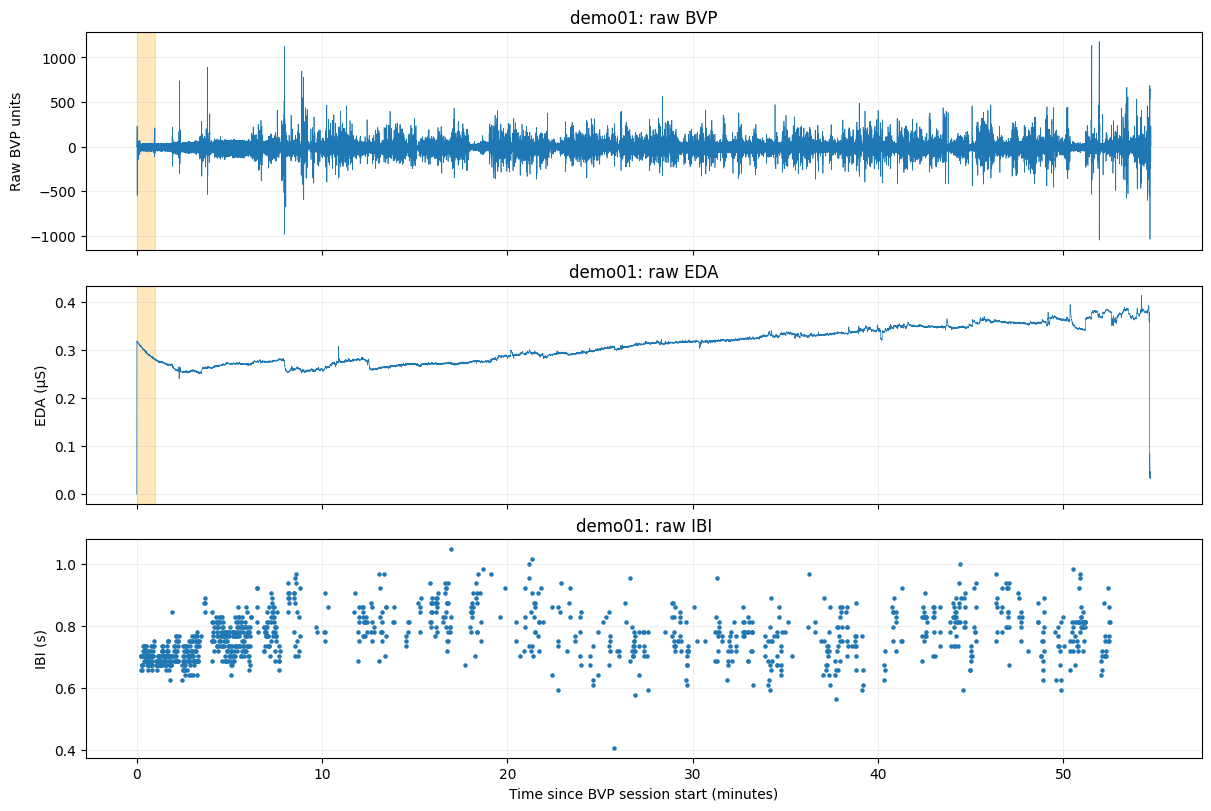

In [46]:
session_start = raw_bvp.index[0]
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, frame, kind, column, unit in [
    (axes[0], raw_bvp, 'BVP', 'raw', 'Raw BVP units'),
    (axes[1], raw_eda, 'EDA', 'raw', 'EDA (μS)'),
    (axes[2], raw_ibi, 'IBI', 'ibi_s', 'IBI (s)')
]:
    minutes = (frame.index - session_start).total_seconds() / 60
    if kind == 'IBI':
        ax.scatter(minutes, frame[column], s=5)
    else:
        ax.plot(minutes, frame[column], linewidth=0.5)
        ax.axvspan(0, STABILIZATION_S / 60, color='orange', alpha=0.25)
    ax.set(title=f'{PARTICIPANT}: raw {kind}', ylabel=unit)
axes[-1].set_xlabel('Time since BVP session start (minutes)')
plt.show()

## 3. Preprocess BVP and EDA at the session level

**BVP:** remove the first 60 seconds → repair missing values if necessary → apply a zero-phase fourth-order Butterworth bandpass → normalize the retained session to [0, 1]. Statistical outlier removal is **not** applied to BVP, matching FANJIE's formal pipeline.

**EDA:** remove the first 60 seconds → flag values more than 2.58 population SDs from the mean and interpolate → apply a normalized 5-second Hann window → remove 5 seconds from **both** smoothed edges → normalize the retained session. The retained timestamp index automatically moves the EDA start forward by another 5 seconds; this prevents misalignment after edge removal.

**Why this order:** filtering before segmentation reduces song-boundary artifacts. Session-level normalization preserves relative amplitudes between songs. SciPy replaces the old BioSPPy wrappers; the Hann convolution and zero-phase Butterworth stages follow the same processing intent. Explicit missing-value repair uses nearest valid values at unbracketed edges, making the interpolation more robust than the legacy forward-only default.

In [47]:
def interpolate_missing(values):
    """Linearly repair missing samples while preserving length and sample timestamps."""
    series = pd.Series(np.asarray(values, dtype=float)).replace([np.inf, -np.inf], np.nan)
    if series.notna().sum() == 0:
        raise ValueError('No valid samples are available for interpolation.')
    return series.interpolate(limit_direction='both').to_numpy()


def minmax_normalize(values):
    """Normalize one retained session; map a constant signal to zeros."""
    span = np.ptp(values)
    return (values - values.min()) / span if span > 0 else np.zeros_like(values)


def preprocess_regular_signal(raw, sampling_rate, kind):
    """Apply the reference's BVP/EDA session pipeline and retain every processing stage."""
    # Drop stabilization samples once; the remaining index keeps its original UTC timing.
    frame = raw.iloc[STABILIZATION_S * sampling_rate:].copy()
    repaired = interpolate_missing(frame['raw'])
    outliers = np.zeros(len(frame), dtype=bool)

    if kind == 'BVP':
        cleaned = repaired
        sos = signal.butter(4, BVP_BAND_HZ, btype='bandpass',
                            fs=sampling_rate, output='sos')
        denoised = signal.sosfiltfilt(sos, cleaned)
    elif kind == 'EDA':
        # Population SD follows the explicit z-score definition used in this notebook.
        sd = repaired.std()
        if sd > 0:
            outliers = np.abs(repaired - repaired.mean()) > OUTLIER_Z * sd
        masked = repaired.copy()
        masked[outliers] = np.nan
        cleaned = interpolate_missing(masked)
        window_size = SMOOTHING_S * sampling_rate
        window = signal.windows.hann(window_size, sym=True)
        denoised = np.convolve(cleaned, window / window.sum(), mode='same')
    else:
        raise ValueError('Only BVP and EDA are supported.')

    frame['cleaned'] = cleaned
    frame['denoised'] = denoised
    frame['outlier'] = outliers
    if kind == 'EDA':
        # Crop both convolution edges without resetting or reconstructing timestamps.
        frame = frame.iloc[window_size:-window_size].copy()
    frame['normalized'] = minmax_normalize(frame['denoised'].to_numpy())
    return frame


processed = {
    'BVP': preprocess_regular_signal(raw_bvp, bvp_fs, 'BVP'),
    'EDA': preprocess_regular_signal(raw_eda, eda_fs, 'EDA')
}

# Check the retained timestamps and the normalized values before any song slicing.
assert processed['BVP'].index[0] == raw_bvp.index[0] + pd.Timedelta(seconds=60)
assert processed['EDA'].index[0] == raw_eda.index[0] + pd.Timedelta(seconds=65)
assert processed['EDA'].index[-1] == raw_eda.index[-1] - pd.Timedelta(seconds=5)
for kind, frame in processed.items():
    assert np.isfinite(frame['normalized']).all()
    assert frame['normalized'].between(0, 1).all()
    print(f"{kind}: {len(frame)} retained samples; {frame['outlier'].sum()} retained outlier flags")

BVP: 206348 retained samples; 0 retained outlier flags
EDA: 12854 retained samples; 2 retained outlier flags


### Compare preprocessing stages

**What and why:** compare raw/cleaned, denoised and normalized values over one short window inside the first selected song. BVP uses a 10-second close-up; EDA uses 60 seconds because its variation is slower. Normalized values in this window need not reach 0 or 1 because the scaling was fitted to the whole retained session.

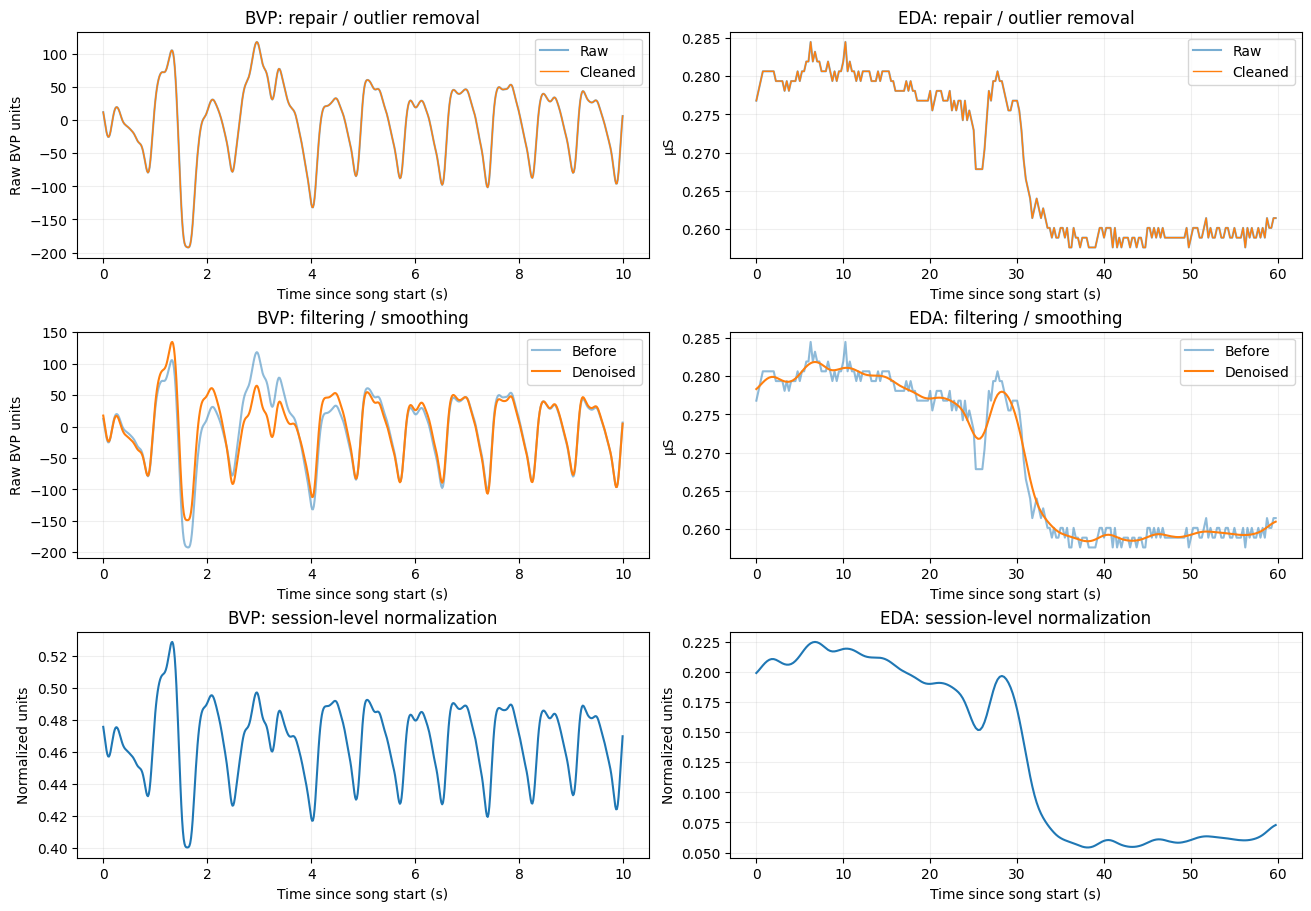

In [48]:
demo_log = music_log.loc[music_log['song_no'].eq(DEMO_SONG_NO)].iloc[0]
fig, axes = plt.subplots(3, 2, figsize=(13, 9), constrained_layout=True)
for col, (kind, zoom_s, raw_unit) in enumerate([('BVP', 10, 'Raw BVP units'), ('EDA', 60, 'μS')]):
    frame = processed[kind]
    start = demo_log['start_time_utc']
    view = frame.loc[(frame.index >= start) & (frame.index < start + pd.Timedelta(seconds=zoom_s))]
    seconds = (view.index - start).total_seconds()
    axes[0, col].plot(seconds, view['raw'], label='Raw', alpha=0.6)
    axes[0, col].plot(seconds, view['cleaned'], label='Cleaned', linewidth=1)
    axes[0, col].set(title=f'{kind}: repair / outlier removal', ylabel=raw_unit)
    axes[0, col].legend()
    axes[1, col].plot(seconds, view['cleaned'], label='Before', alpha=0.5)
    axes[1, col].plot(seconds, view['denoised'], label='Denoised')
    axes[1, col].set(title=f'{kind}: filtering / smoothing', ylabel=raw_unit)
    axes[1, col].legend()
    axes[2, col].plot(seconds, view['normalized'])
    axes[2, col].set(title=f'{kind}: session-level normalization', ylabel='Normalized units')
    for ax in axes[:, col]:
        ax.set_xlabel('Time since song start (s)')
plt.show()

## 4. Segment the three signals using music playback times

**What:** select each song's BVP/EDA samples using `[start, end)` and IBI events using `start < beat_time < end`, reproducing the reference's IBI endpoint convention. `song_no` plus `song_id` identifies a playback; repeated plays of the same song remain separate records.

**Why:** filtering must not change the time reference. We slice by the retained UTC timestamps, so the 60-second stabilization exclusion and 5-second EDA edge crop are already accounted for. Every chunk retains its actual timestamps. IBI is sliced by the device's event times, not by a fixed sample rate or accumulated intervals. An interval is assigned by its event timestamp, as in FANJIE; an interval ending inside the song can begin before its boundary.

The alignment table compares actual BVP/EDA sample counts with the counts implied by the log. IBI event counts measure available detections, not continuous coverage.

In [49]:
def slice_song(frame, start, end, is_ibi=False):
    """Select one playback by real timestamps, preserving the reference's endpoint rules."""
    after_start = frame.index > start if is_ibi else frame.index >= start
    return frame.loc[after_start & (frame.index < end)].copy()


# The only loop over records is this participant's own music log.
chunks = {}
alignment_rows = []
for song in music_log.itertuples(index=False):
    start, end = song.start_time_utc, song.end_time_utc
    per_song = {
        'BVP': slice_song(processed['BVP'], start, end),
        'EDA': slice_song(processed['EDA'], start, end),
        'IBI': slice_song(raw_ibi, start, end, is_ibi=True)
    }
    for frame in per_song.values():
        frame.insert(0, 'time_from_song_s', (frame.index - start).total_seconds())
    chunks[song.song_no] = per_song
    bvp_n, eda_n, ibi_n = (len(per_song[kind]) for kind in ['BVP', 'EDA', 'IBI'])
    alignment_rows.append({
        'participant_id': PARTICIPANT, 'song_no': song.song_no, 'song_id': song.song_id,
        'start_time_utc': start, 'end_time_utc': end, 'play_duration_s': song.play_duration_s,
        'reported_time_play_s': song.time_play, 'reported_duration_s': song.duration,
        'BVP_expected_samples': round(song.play_duration_s * bvp_fs), 'BVP_samples': bvp_n,
        'EDA_expected_samples': round(song.play_duration_s * eda_fs), 'EDA_samples': eda_n,
        'BVP_coverage_s': bvp_n / bvp_fs, 'EDA_coverage_s': eda_n / eda_fs,
        'BVP_complete': bvp_n == round(song.play_duration_s * bvp_fs),
        'EDA_complete': eda_n == round(song.play_duration_s * eda_fs), 'IBI_intervals': ibi_n
    })

alignment = pd.DataFrame(alignment_rows)
display(alignment[['song_no', 'song_id', 'play_duration_s', 'BVP_coverage_s',
                   'EDA_coverage_s', 'BVP_complete', 'EDA_complete', 'IBI_intervals']])

,song_no,song_id,play_duration_s,BVP_coverage_s,EDA_coverage_s,BVP_complete,EDA_complete,IBI_intervals
0,0,262957,147.0,147.0,147.0,True,True,40
1,1,1071844,61.0,61.0,61.0,True,True,14
2,2,1094515,46.0,46.0,46.0,True,True,19
3,3,519565,39.0,39.0,39.0,True,True,19
4,4,1130631,45.0,45.0,45.0,True,True,1
5,5,1167225,58.0,58.0,58.0,True,True,4
6,6,187045,45.0,45.0,45.0,True,True,21
7,7,1083659,64.0,64.0,64.0,True,True,8
8,8,262957,32.0,32.0,32.0,True,True,3
9,9,737755,51.0,51.0,51.0,True,True,8


## 5. Define the same 38 features as the simplified workshop

**BVP (4):** mean, population SD, MFAD and MSAD. MFAD/MSAD are absolute sample differences, not time derivatives.

**EDA (22):** the four basic features; min/max/range/median; slope/intercept; tonic mean/SD/slope/intercept; SCR count/rate; and SCR amplitude, rise-time and recovery-time means/SDs. Slopes use seconds from the beginning of the selected chunk. EDA amplitudes now use **session-normalized units**, and SCR rate is events per second. NeuroKit2's high-pass decomposition and NeuroKit peak detector match the simplified workshop. They replace the original legacy NeuroKit defaults and are not guaranteed to give identical EDA results to the old library.

**IBI (12):** mean_nni, SDNN, SDSD, median_nni, range_nni, nni_50, pNN50, nni_20, pNN20, RMSSD, CVSD and CVNNI. Clean each song's IBI using 300–2000 ms limits, linear interpolation, the Malik 20% rule and another interpolation. Keep real timestamps throughout. SDNN uses sample SD (ddof=1); SDSD uses population SD (ddof=0). pNN20/pNN50 are percentages, CVSD/CVNNI are ratios, and interval-valued HRV features are in milliseconds.

Empty or insufficient IBI chunks retain their playback row and unavailable values remain NaN. We do not invent beats or fill missing features with across-song averages.

In [50]:
def basic_features(values, prefix):
    """Summarize level, spread and absolute first/second sample differences."""
    x = np.asarray(values, dtype=float)
    return {
        f'{prefix}_mean': np.mean(x), f'{prefix}_std': np.std(x),
        f'{prefix}_MFAD': np.mean(np.abs(np.diff(x))),
        f'{prefix}_MSAD': np.mean(np.abs(np.diff(x, n=2)))
    }


def summarize_valid(values, prefix):
    """Compute population mean/SD from valid response measurements; keep missingness explicit."""
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    return {f'{prefix}_mean': x.mean() if len(x) else np.nan,
            f'{prefix}_std': x.std() if len(x) else np.nan}


def extract_eda_features(values, sampling_rate):
    """Extract the workshop's 22 EDA features and return decomposition/SCR details for plotting."""
    x = np.asarray(values, dtype=float)
    seconds = np.arange(len(x)) / sampling_rate
    slope, intercept = np.polyfit(seconds, x, 1)
    features = basic_features(x, 'EDA')
    features.update(EDA_min=x.min(), EDA_max=x.max(), EDA_range=np.ptp(x),
                    EDA_median=np.median(x), EDA_slope=slope, EDA_intercept=intercept)

    # Decomposition adds tonic/phasic components without repeating session cleaning.
    components = nk.eda_phasic(x, sampling_rate=sampling_rate, method='highpass')
    if np.ptp(x) == 0:
        scr = {name: np.array([]) for name in [
            'SCR_Peaks', 'SCR_Onsets', 'SCR_Recovery', 'SCR_Amplitude',
            'SCR_RiseTime', 'SCR_RecoveryTime']}
    else:
        _, scr = nk.eda_peaks(components['EDA_Phasic'], sampling_rate=sampling_rate,
                             method='neurokit', amplitude_min=0.1)
    tonic = components['EDA_Tonic'].to_numpy()
    tonic_slope, tonic_intercept = np.polyfit(seconds, tonic, 1)
    features.update(EDA_tonic_mean=tonic.mean(), EDA_tonic_std=tonic.std(),
                    EDA_tonic_slope=tonic_slope, EDA_tonic_intercept=tonic_intercept,
                    SCR_num=len(scr['SCR_Peaks']), SCR_rate=len(scr['SCR_Peaks'])/(len(x)/sampling_rate))
    for field, prefix in [('SCR_Amplitude', 'SCR_peak'), ('SCR_RiseTime', 'SCR_rise_time'),
                          ('SCR_RecoveryTime', 'SCR_recovery_time')]:
        features.update(summarize_valid(scr[field], prefix))
    return features, components, scr

In [51]:
def clean_ibi_chunk(frame):
    """Clean one song's IBI in milliseconds without changing its observed event timestamps."""
    result = frame.copy()
    rr = result['ibi_s'].to_numpy(dtype=float) * 1000
    valid = np.isfinite(rr) & (rr >= 300) & (rr <= 2000)
    result['range_rejected'] = ~valid
    result['malik_rejected'] = False
    result['nn_ms'] = np.nan
    if not valid.any():
        return result

    # Repair range outliers before testing adjacent intervals for abrupt changes.
    masked = rr.copy()
    masked[~valid] = np.nan
    rr_clean = interpolate_missing(masked)
    nn = rr_clean.copy()
    skip_next = False
    for i in range(len(rr_clean) - 1):
        if skip_next:
            skip_next = False
            continue
        if abs(rr_clean[i + 1] - rr_clean[i]) > 0.2 * rr_clean[i]:
            nn[i + 1] = np.nan
            skip_next = True  # Match hrv-analysis: skip comparison after a rejected beat.
    result['malik_rejected'] = np.isnan(nn)
    result['nn_ms'] = interpolate_missing(nn)
    return result


def extract_ibi_features(cleaned):
    """Extract time-domain HRV; leave unsupported features missing for short/empty chunks."""
    names = ['mean_nni', 'sdnn', 'sdsd', 'median_nni', 'range_nni', 'nni_50',
             'pnni_50', 'nni_20', 'pnni_20', 'rmssd', 'cvsd', 'cvnni']
    features = dict.fromkeys(names, np.nan)
    nn = cleaned['nn_ms'].to_numpy(dtype=float)
    nn = nn[np.isfinite(nn)]
    if len(nn) == 0:
        return features, 'empty_or_no_valid_intervals'

    features.update(mean_nni=nn.mean(), median_nni=np.median(nn), range_nni=np.ptp(nn))
    if len(nn) < 2:
        return features, 'insufficient_intervals'

    differences = np.diff(nn)
    sdnn = nn.std(ddof=1)
    rmssd = np.sqrt(np.mean(differences ** 2))
    features.update(
        sdnn=sdnn, sdsd=differences.std(), rmssd=rmssd,
        nni_50=int(np.sum(np.abs(differences) > 50)), pnni_50=100*np.mean(np.abs(differences) > 50),
        nni_20=int(np.sum(np.abs(differences) > 20)), pnni_20=100*np.mean(np.abs(differences) > 20),
        cvsd=rmssd/nn.mean(), cvnni=sdnn/nn.mean()
    )
    return features, 'ok' if len(nn) >= 3 else 'two_intervals'

## 6. Extract features for demo01's song playbacks

**What and why:** apply the feature functions to the already aligned chunks. Keep one feature row per `(participant_id, song_no, song_id)`. A repeated `song_id` is allowed because the listening order identifies a separate playback. Keep the IBI rejection counts and availability status beside the results.

The supplied demo01 data have full BVP/EDA coverage for the logged songs; the explicit length check below stops execution rather than silently extracting features from an empty continuous chunk.

In [52]:
feature_rows = []
eda_details = {}
for song in music_log.itertuples(index=False):
    per_song = chunks[song.song_no]
    bvp = per_song['BVP']['normalized'].to_numpy()
    eda = per_song['EDA']['normalized'].to_numpy()
    assert len(bvp) >= 3 and len(eda) >= 3, f'Empty/short continuous chunk: {song.song_no}'

    bvp_features = basic_features(bvp, 'BVP')
    eda_features, components, scr = extract_eda_features(eda, eda_fs)
    per_song['IBI'] = clean_ibi_chunk(per_song['IBI'])
    ibi_features, ibi_status = extract_ibi_features(per_song['IBI'])
    eda_details[song.song_no] = {'components': components, 'scr': scr}

    feature_rows.append({
        'participant_id': PARTICIPANT, 'song_no': song.song_no, 'song_id': song.song_id,
        'play_duration_s': song.play_duration_s,
        **bvp_features, **eda_features, **ibi_features,
        'IBI_intervals': len(per_song['IBI']),
        'IBI_range_rejected': int(per_song['IBI']['range_rejected'].sum()),
        'IBI_malik_rejected': int(per_song['IBI']['malik_rejected'].sum()), 'IBI_status': ibi_status
    })

features = pd.DataFrame(feature_rows).replace([np.inf, -np.inf], np.nan)
feature_names = list(bvp_features) + list(eda_features) + list(ibi_features)
assert len(feature_names) == 38
display(features[['song_no', 'song_id', 'BVP_mean', 'EDA_tonic_mean', 'SCR_num',
                  'mean_nni', 'rmssd', 'IBI_intervals', 'IBI_status']])
print('Missing measurements by feature:')
display(features[feature_names].isna().sum().loc[lambda counts: counts > 0].to_frame('Missing songs'))

,song_no,song_id,BVP_mean,EDA_tonic_mean,SCR_num,mean_nni,rmssd,IBI_intervals,IBI_status
0,0,262957,0.467781,0.115835,10,801.208450,61.848308,40,ok
1,1,1071844,0.467763,0.136672,7,852.717643,62.802786,14,ok
2,2,1094515,0.468027,0.144922,8,853.246211,71.653418,19,ok
3,3,519565,0.467869,0.172260,6,845.022211,86.413510,19,ok
4,4,1130631,0.467661,0.197447,5,968.794000,NaN,1,insufficient_intervals
5,5,1167225,0.467802,0.275509,4,796.911250,77.605976,4,ok
6,6,187045,0.467714,0.299332,6,830.395119,114.131736,21,ok
7,7,1083659,0.467734,0.290788,7,785.192125,123.602510,8,ok
8,8,262957,0.468088,0.318908,5,682.323000,31.251000,3,ok
9,9,737755,0.467765,0.368189,7,725.619250,85.483780,8,ok


Missing measurements by feature:


,Missing songs
sdnn,1
sdsd,1
nni_50,1
pnni_50,1
nni_20,1
pnni_20,1
rmssd,1
cvsd,1
cvnni,1


## 7. Inspect one aligned song and its features

**What and why:** use the same `DEMO_SONG_NO` for every panel so the three channels refer to the same playback. The x-axis is time since the logged song start. IBI points use the original device event times, including gaps. Empty sections of the IBI plot are not filled by accumulating intervals.

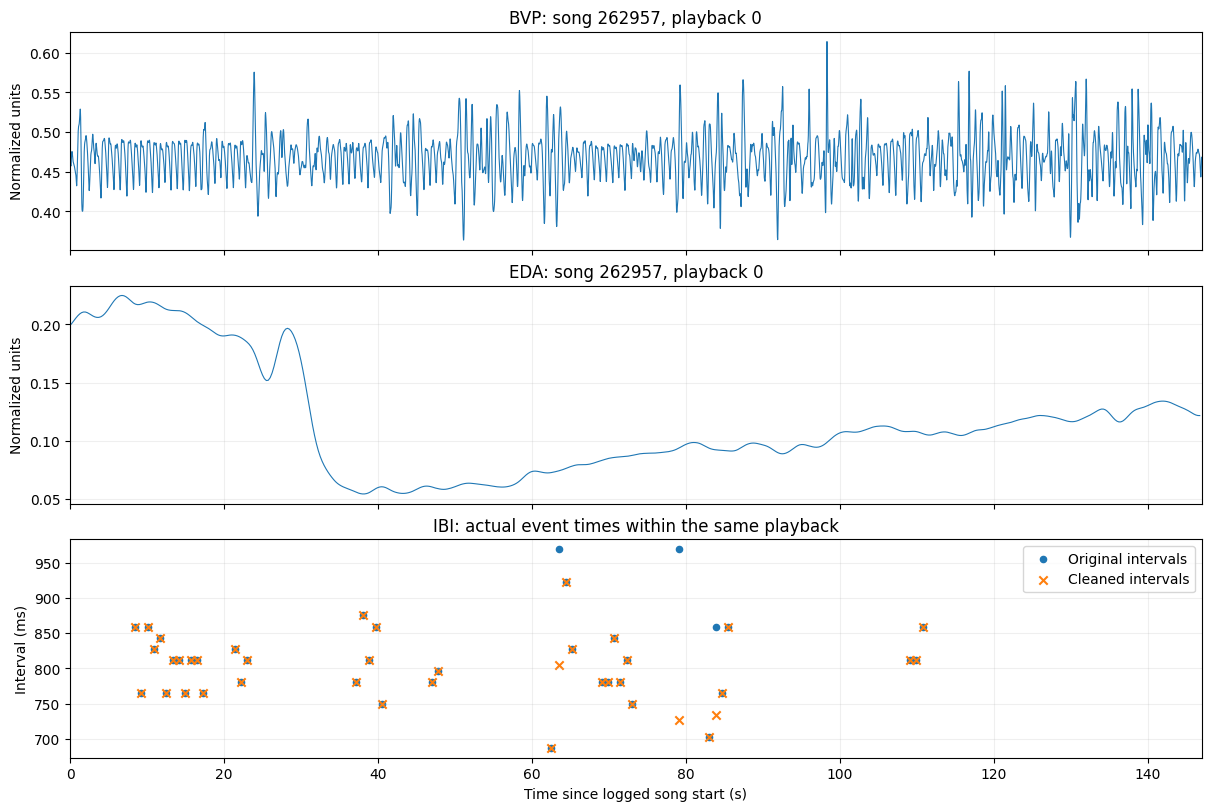

In [53]:
example = chunks[DEMO_SONG_NO]
song_id = int(demo_log['song_id'])
duration = float(demo_log['play_duration_s'])
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, kind in zip(axes[:2], ['BVP', 'EDA']):
    frame = example[kind]
    ax.plot(frame['time_from_song_s'], frame['normalized'], linewidth=0.8)
    ax.set(title=f'{kind}: song {song_id}, playback {DEMO_SONG_NO}', ylabel='Normalized units')
ibi_view = example['IBI']
axes[2].scatter(ibi_view['time_from_song_s'], ibi_view['ibi_s']*1000, label='Original intervals', s=20)
axes[2].scatter(ibi_view['time_from_song_s'], ibi_view['nn_ms'], label='Cleaned intervals', marker='x')
axes[2].set(title='IBI: actual event times within the same playback', ylabel='Interval (ms)', xlim=(0, duration))
axes[2].legend()
axes[-1].set_xlabel('Time since logged song start (s)')
plt.show()

### EDA decomposition and response features

**What and why:** show the tonic background, phasic changes and detected SCR landmarks. The response amplitude chart makes the SCR amplitude summaries visible. A missing recovery point remains missing rather than being treated as a zero-second recovery.

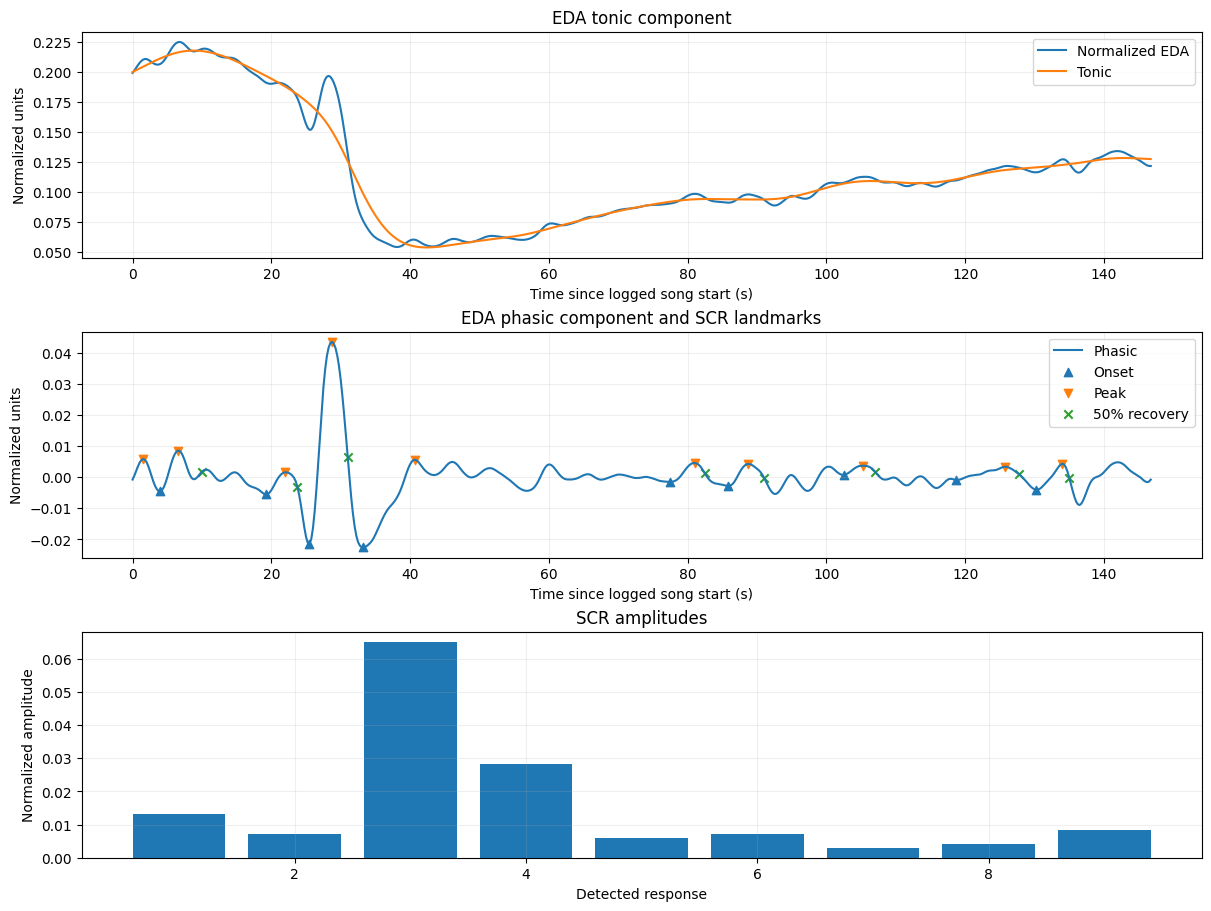

In [54]:
details = eda_details[DEMO_SONG_NO]
components, scr = details['components'], details['scr']
seconds = example['EDA']['time_from_song_s'].to_numpy()
tonic = components['EDA_Tonic'].to_numpy()
phasic = components['EDA_Phasic'].to_numpy()
fig, axes = plt.subplots(3, 1, figsize=(12, 9), constrained_layout=True)
axes[0].plot(seconds, example['EDA']['normalized'], label='Normalized EDA')
axes[0].plot(seconds, tonic, label='Tonic')
axes[0].set(ylabel='Normalized units', title='EDA tonic component')
axes[0].legend()
axes[1].plot(seconds, phasic, label='Phasic')
for field, marker, label in [('SCR_Onsets', '^', 'Onset'), ('SCR_Peaks', 'v', 'Peak'),
                              ('SCR_Recovery', 'x', '50% recovery')]:
    indices = np.asarray(scr[field], dtype=float)
    indices = indices[np.isfinite(indices) & (indices >= 0) & (indices < len(seconds))].astype(int)
    axes[1].scatter(seconds[indices], phasic[indices], marker=marker, label=label)
axes[1].set(ylabel='Normalized units', title='EDA phasic component and SCR landmarks')
axes[1].legend()
for ax in axes[:2]:
    ax.set_xlabel('Time since logged song start (s)')
axes[2].bar(np.arange(len(scr['SCR_Amplitude'])), scr['SCR_Amplitude'])
axes[2].set(xlabel='Detected response', ylabel='Normalized amplitude', title='SCR amplitudes')
plt.show()

### IBI variation and song-level feature summaries

**What and why:** plot the differences used in RMSSD/pNN20/pNN50 and compare SDNN, SDSD and RMSSD in the same units. These summaries describe only the available interval sequence. Adjacent entries may be separated by missing detections, so they cannot establish continuous HRV throughout the song.

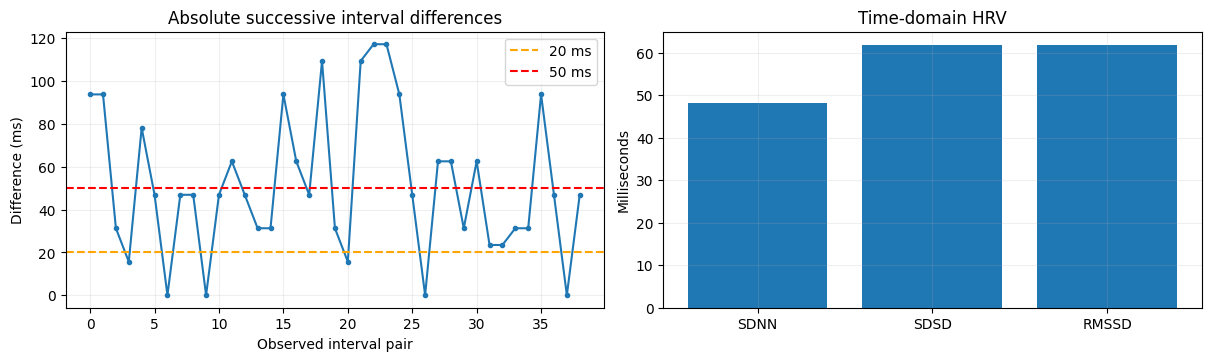

,Feature value
BVP_mean,0.467781
BVP_std,0.029121
BVP_MFAD,0.003097
BVP_MSAD,0.000719
EDA_mean,0.115965
EDA_std,0.048299
EDA_MFAD,0.000877
EDA_MSAD,0.000199
EDA_min,0.054236
EDA_max,0.224964


In [55]:
example_features = features.loc[features['song_no'].eq(DEMO_SONG_NO)].iloc[0]
nn = example['IBI']['nn_ms'].dropna().to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
axes[0].plot(np.abs(np.diff(nn)), '.-')
axes[0].axhline(20, color='orange', linestyle='--', label='20 ms')
axes[0].axhline(50, color='red', linestyle='--', label='50 ms')
axes[0].set(title='Absolute successive interval differences', xlabel='Observed interval pair', ylabel='Difference (ms)')
axes[0].legend()
axes[1].bar(['SDNN', 'SDSD', 'RMSSD'], example_features[['sdnn', 'sdsd', 'rmssd']].to_numpy(dtype=float))
axes[1].set(title='Time-domain HRV', ylabel='Milliseconds')
plt.show()
display(example_features[feature_names].to_frame('Feature value'))

### Compare selected features across playbacks

**What and why:** inspect BVP local variation, EDA tonic level, SCR rate and IBI RMSSD across the same participant's listening order. Separate axes keep their different units explicit. Missing HRV points remain gaps.

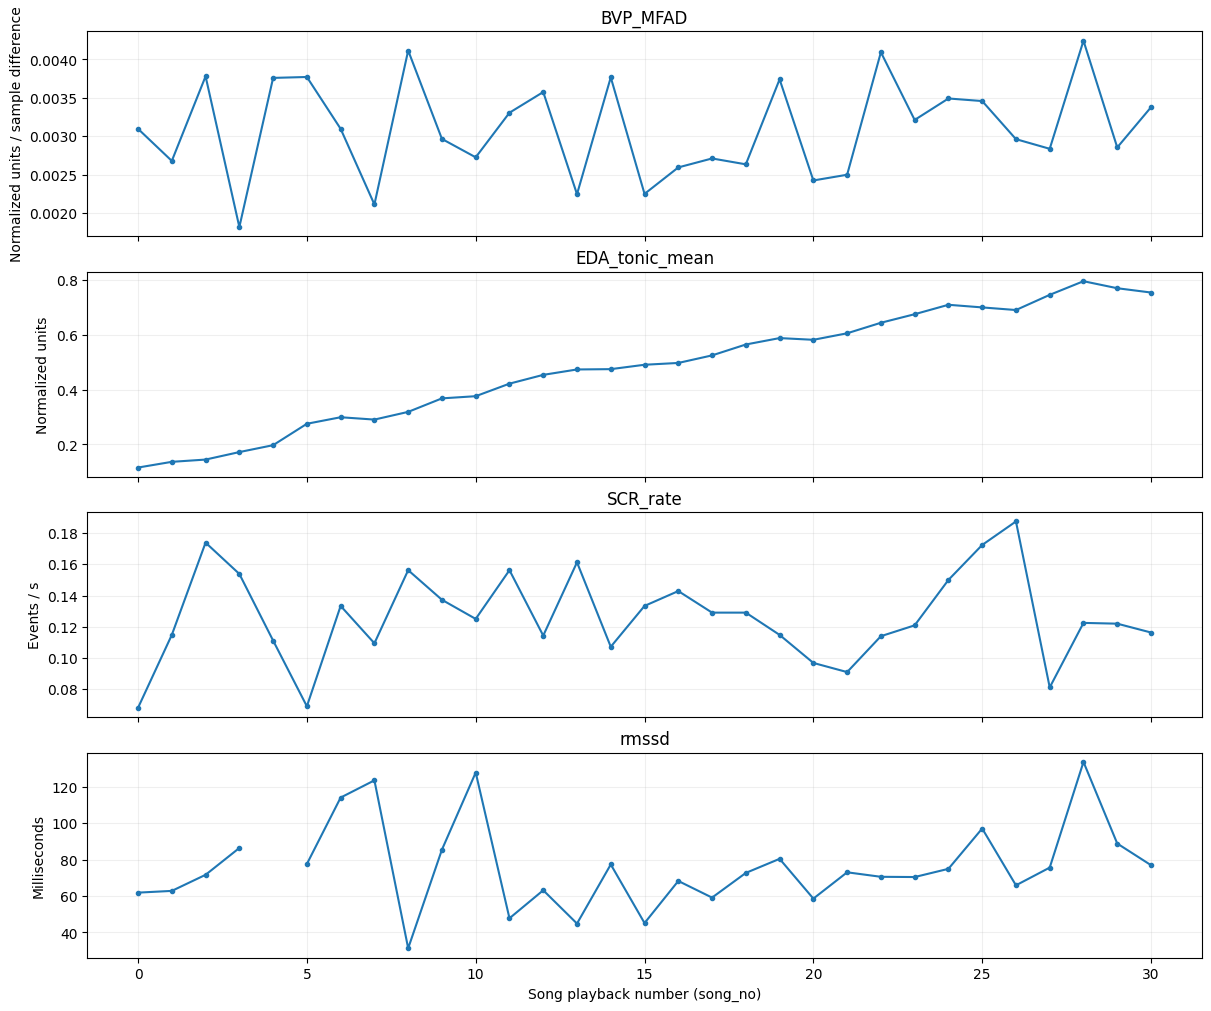

In [56]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True, constrained_layout=True)
for ax, field, unit in zip(axes, ['BVP_MFAD', 'EDA_tonic_mean', 'SCR_rate', 'rmssd'],
                           ['Normalized units / sample difference', 'Normalized units', 'Events / s', 'Milliseconds']):
    ax.plot(features['song_no'], features[field], '.-')
    ax.set(title=field, ylabel=unit)
axes[-1].set_xlabel('Song playback number (song_no)')
plt.show()

## 8. Check alignment and save results

**What and why:** verify the time boundaries, sample counts, row identities and normalized values before exporting. The feature table keeps `participant_id`, `song_no` and `song_id` so every row can be linked to its source playback. The alignment CSV keeps both timestamp-derived duration and the log's original duration fields.

Outputs are written only under `demo01_raw_pipeline_outputs/`: `demo01_features.csv`, `music_alignment.csv`, the two preprocessed continuous sessions, timestamped per-song chunks and processing settings. BVP/EDA chunks include all preprocessing stages; IBI chunks include original seconds, cleaned milliseconds and rejection flags. Existing source files and the earlier workshop notebook remain untouched.

In [57]:
# Validate the output identity and sample coverage for every logged playback.
assert len(features) == len(music_log) == len(chunks)
assert features['participant_id'].eq(PARTICIPANT).all()
assert not features.duplicated(['participant_id', 'song_no', 'song_id']).any()
assert alignment[['BVP_complete', 'EDA_complete']].all().all(), 'Some playbacks have incomplete coverage.'
for song in music_log.itertuples(index=False):
    for kind, frame in chunks[song.song_no].items():
        if len(frame):
            assert (frame.index >= song.start_time_utc).all()
            assert (frame.index < song.end_time_utc).all()
            if kind == 'IBI':
                assert (frame.index > song.start_time_utc).all()
            else:
                assert frame['normalized'].between(0, 1).all()

# Export reusable data without modifying any files in RAW_DIR.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
features.to_csv(OUTPUT_DIR / 'demo01_features.csv', index=False)
alignment.to_csv(OUTPUT_DIR / 'music_alignment.csv', index=False)
for kind, frame in processed.items():
    frame.to_csv(OUTPUT_DIR / f'{kind}_preprocessed_session.csv', index=True)
for song in music_log.itertuples(index=False):
    filename = f'{song.song_no}_{song.song_id}.csv'
    for kind, frame in chunks[song.song_no].items():
        folder = OUTPUT_DIR / 'chunks' / kind
        folder.mkdir(parents=True, exist_ok=True)
        frame.to_csv(folder / filename, index=True)

# Save the parameters and software versions needed to reproduce this run.
settings = {
    'participant_id': PARTICIPANT, 'raw_directory': str(RAW_DIR),
    'log_timezone': LOG_TIMEZONE, 'stabilization_seconds': STABILIZATION_S,
    'bvp_band_hz': BVP_BAND_HZ, 'butterworth_order': 4,
    'eda_outlier_z': OUTLIER_Z, 'eda_hann_seconds': SMOOTHING_S,
    'eda_crop_seconds_each_edge': SMOOTHING_S,
    'normalization': 'BVP/EDA retained session min-max; IBI remains in physical interval units',
    'alignment': 'BVP/EDA [start,end); IBI (start,end); boundaries from MyLog start_time/end_time',
    'eda_decomposition': 'NeuroKit2 highpass', 'scr_detector': 'neurokit; amplitude_min=0.1',
    'ibi_processing': '300-2000 ms; linear interpolation; Malik 20%; linear interpolation',
    'feature_count': len(feature_names),
    'versions': {name: metadata.version(name) for name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'neurokit2']}
}
(OUTPUT_DIR / 'processing_settings.json').write_text(json.dumps(settings, indent=2))
print(f'Validated and saved {len(features)} playbacks with {len(feature_names)} signal features each.')
print(f'Output directory: {OUTPUT_DIR.resolve()}')

Validated and saved 31 playbacks with 38 signal features each.
Output directory: /content/drive/MyDrive/ISMIR 2026 tutorial/Colab Notebooks/01 Physiological Signal Processing/demo01_raw_pipeline_outputs


Cite us:
Hu, X., Li, F., & Liu, R. (2022). Detecting Music-Induced Emotion Based on Acoustic Analysis and Physiological Sensing: A Multimodal Approach. Applied Sciences, 12(18), 9354. https://doi.org/10.3390/app12189354

Data Availability: https://doi.org/10.25442/hku.21080821